# Monte Carlo para redes: simulación y valoración de la call asiática

**Módulo de simulación:** `packages/montecarlo.py`. **Procedencia de los parámetros:** `outputs/parametros_montecarlo.json`, estimados sobre `Datos/Transformados/dowjones_diario_2016_2025.csv`.

Se conserva la estructura y la simulación de la entrega original, y se exportan dos muestras. El entrenamiento de `10_Mining.ipynb` utiliza la muestra condicionada; la independiente se conserva como referencia para comparar la valoración con y sin tramo inicial común:

- **Cartera y contrato:** CAT, MRK y MSFT; precios iniciales normalizados a 1; strike 3; tipo libre de riesgo del 1 %; sin dividendos.
- **Simulación:** 100.000 trayectorias, 20 pasos trimestrales y cinco años, con semilla 42.
- **Muestra condicionada:** comparte los cinco primeros pasos hasta 1,25 años, reproduce los resultados de la entrega y es la entrada del entrenamiento actual de `10_Mining.ipynb`.
- **Muestra independiente:** las trayectorias son independientes entre sí desde el primer paso, con la correlación entre activos incorporada mediante Cholesky. Permite comparar la valoración inicial incondicional con la valoración condicionada al tramo común.
- **Prima por instante:** se valora la primera historia de la muestra independiente utilizando únicamente su pasado en cada fecha. Es una referencia adicional de valoración y no forma parte del entrenamiento actual de `10_Mining.ipynb`.

Este notebook se ejecuta desde la raíz del repositorio y utiliza `packages/montecarlo.py` y `packages/bbva_graficos.py`. No necesita leer el CSV ni descargar cotizaciones. Las dependencias son NumPy, pandas, Matplotlib, IPython, Seaborn y Plotly.

Los gráficos se guardan en `Graficos/` con nombres propios de esta versión. Los tres archivos para intercambio se generan en `Datos/Transformados/`. El notebook original de entrega no se modifica.


In [1]:
from time import perf_counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from packages import montecarlo as mc
from packages.bbva_graficos import configurar_graficos, guardar_mpl, cerrar_grafico, fmt_es, BBVA, PALETA

carpeta_graficos = configurar_graficos()
pd.options.display.float_format = lambda valor: fmt_es(valor, 6)

# La versión actual del módulo gráfico no incluye esta anotación.
def anotar_fuente(fig, texto):
    fig.text(0.01, -0.01, f"Fuente: {texto}", fontsize=11, color=BBVA["marino"])


## 1. Cartera y parámetros históricos

Las volatilidades anuales y las correlaciones proceden de la selección de cartera realizada sobre `Datos/Transformados/dowjones_diario_2016_2025.csv`. Se emplean los rendimientos logarítmicos diarios del **05/01/2016 al 31/12/2025**. La volatilidad se anualizó con **252 sesiones bursátiles** y la correlación se calculó con el coeficiente de Pearson.

Los valores de `outputs/parametros_montecarlo.json`, con seis decimales, se centralizan en `packages/montecarlo.py`. El notebook y los scripts que importen ese módulo comparten los mismos parámetros y funciones. El CSV y el JSON documentan la procedencia; no se leen durante la simulación.

El histórico se utiliza para estimar las volatilidades y las correlaciones. El crecimiento esperado de las trayectorias se fija en la tasa libre de riesgo, de acuerdo con el marco de valoración neutral al riesgo.


In [2]:
activos = mc.ACTIVOS
sigma = mc.SIGMA
rho = mc.RHO


## 2. Configuración de la simulación

El horizonte de cinco años se divide en **20 pasos de 0,25 años**. Los instantes simulados son $t_j=j\Delta t$, con $j=1,\ldots,20$: desde $t=0,25$ hasta $t=5$.

Se genera una sola trayectoria inicial de cinco pasos y se comparte entre las 100.000 simulaciones. Este tramo alcanza **1,25 años**. A partir del sexto paso, cada simulación continúa con nuevos incrementos aleatorios independientes de las demás, manteniendo la correlación entre los tres activos.

El precio inicial $S_0$ corresponde a $t=0$ y se incluye en la representación de las trayectorias. Las medias geométricas del payoff utilizan las **20 observaciones futuras**, incluido el tramo común, sin añadir el precio inicial como una observación más.

La tasa libre de riesgo es $r=0,01$ para los tres activos. Las volatilidades anuales y el tipo de interés se expresan en fracción, por lo que **0,01 equivale al 1 %**. Se utilizan 100.000 continuaciones para reducir el error de muestreo y la semilla **42** para reproducir el tramo común y los escenarios posteriores.


In [3]:
num_sims = 100_000
num_pasos = mc.NUM_PASOS
TTM = mc.TTM
dt = mc.DT
S0 = mc.S0
r = mc.R
strike = mc.STRIKE
semilla = 42
n_pasos_comunes = 5
t_bifurcacion = n_pasos_comunes * dt

df_configuracion = pd.DataFrame({
    "Parámetro": [
        "Simulaciones", "Pasos trimestrales", "Horizonte",
        "Duración del paso", "Pasos comunes", "Final del tramo común",
        "Tipo libre de riesgo anual", "Strike normalizado", "Semilla",
    ],
    "Valor": [
        fmt_es(num_sims), fmt_es(num_pasos), f"{fmt_es(TTM)} años",
        f"{fmt_es(dt, 2)} años", fmt_es(n_pasos_comunes),
        f"{fmt_es(t_bifurcacion, 2)} años", f"{fmt_es(100 * r, 2)} %",
        fmt_es(strike), fmt_es(semilla),
    ],
})
df_activos = pd.DataFrame(
    {"S0 normalizado": S0, "Volatilidad anual": sigma},
    index=pd.Index(activos, name="Activo"),
)
df_correlacion = pd.DataFrame(rho, index=activos, columns=activos)

display(Markdown("**Configuración de la simulación**"), df_configuracion)
display(Markdown("**Parámetros de las acciones (volatilidad anual en fracción)**"), df_activos.round(6))
display(Markdown("**Matriz de correlaciones**"), df_correlacion.round(6))


**Configuración de la simulación**

,Parámetro,Valor
0,Simulaciones,100.000
1,Pasos trimestrales,20
2,Horizonte,5 años
3,Duración del paso,"0,25 años"
4,Pasos comunes,5
5,Final del tramo común,"1,25 años"
6,Tipo libre de riesgo anual,"1,00 %"
7,Strike normalizado,3
8,Semilla,42


**Parámetros de las acciones (volatilidad anual en fracción)**

,S0 normalizado,Volatilidad anual
Activo,,
CAT,"1,000000","0,304449"
MRK,"1,000000","0,226614"
MSFT,"1,000000","0,267572"


**Matriz de correlaciones**

,CAT,MRK,MSFT
CAT,"1,000000","0,249833","0,394764"
MRK,"0,249833","1,000000","0,276564"
MSFT,"0,394764","0,276564","1,000000"


## 3. Generación de la matriz de trayectorias X

Para cada activo $k$, el movimiento browniano geométrico se simula mediante:

$$
S_j^k=S_0^k\exp\left(
\sum_{\ell=1}^{j}
\left[
\left(r-\frac{\sigma_k^2}{2}\right)\Delta t
+\sigma_k\sqrt{\Delta t}\,Z_\ell^k
\right]
\right).
$$

Se generan normales estándar y se aplica la descomposición de Cholesky $\rho=LL^\top$. Al organizar los vectores normales por filas, la multiplicación **Z @ L.T** incorpora las correlaciones entre CAT, MRK y MSFT. El término $\sqrt{\Delta t}\,Z$ representa los incrementos brownianos y $\sigma$ ajusta su magnitud para cada activo.

`mc.simular_historia` genera una única historia inicial de cinco pasos. `mc.simular_continuaciones` la replica entre simulaciones y genera los 15 pasos posteriores de forma independiente para cada continuación. Los precios comunes pueden cambiar de un trimestre al siguiente; lo que se mantiene igual es su valor entre las 100.000 trayectorias en cada uno de esos cinco instantes.

El módulo utiliza **np.cumsum** para acumular los incrementos logarítmicos sobre el eje temporal y **np.exp** para obtener los precios normalizados. Las continuaciones parten del último precio conocido y conservan la historia observada. El cálculo de las 100.000 trayectorias se realiza con operaciones matriciales, sin bucles.

**X** tiene forma **(100000, 20, 3)**, con ejes **(simulación, instante, activo)**. El tiempo mostrado mide exclusivamente la generación de X, sin incluir las tablas, los gráficos ni el cálculo posterior del payoff.


In [4]:
inicio = perf_counter()
L = mc.L
rng = np.random.default_rng(semilla)
historia = mc.simular_historia(n_pasos_comunes, rng)
X = mc.simular_continuaciones(historia, num_sims, rng)
tiempo_simulacion = perf_counter() - inicio

tiempos = mc.TIEMPOS
simulaciones = pd.Index(np.arange(1, num_sims + 1), name="Simulación")
anios = np.arange(1, TTM + 1)
indices_anuales = (anios / dt).astype(int) - 1

df_simulacion = pd.DataFrame({
    "Forma de X": [str(X.shape)],
    "Tiempo de generación (s)": [tiempo_simulacion],
})
display(Markdown(f"**Matriz completa generada con semilla {semilla}**"), df_simulacion.round(4))

df_tramo_comun = pd.DataFrame(
    np.vstack((S0, X[0, :n_pasos_comunes, :])),
    index=pd.Index(np.r_[0, tiempos[:n_pasos_comunes]], name="Tiempo (años)"),
    columns=activos,
)
display(Markdown("**Precios compartidos por todas las simulaciones en el tramo inicial**"), df_tramo_comun.round(4))


**Matriz completa generada con semilla 42**

,Forma de X,Tiempo de generación (s)
0,"(100000, 20, 3)","0,160400"


**Precios compartidos por todas las simulaciones en el tramo inicial**

,CAT,MRK,MSFT
Tiempo (años),,,
"0,000000","1,000000","1,000000","1,000000"
"0,250000","1,038000","0,896400","1,077300"
"0,500000","1,187000","0,740300","0,916600"
"0,750000","1,199300","0,714800","0,907900"
"1,000000","1,043800","0,765400","0,967700"
"1,250000","1,044800","0,864400","1,049400"


### Abanico general de escenarios a cinco años

El gráfico resume las **100.000 simulaciones** durante los **cinco años completos**. El tramo inicial, sombreado en gris, es común a todas las trayectorias hasta **1,25 años**; después comienzan las continuaciones independientes.

- La banda azul clara delimita los **percentiles 5 y 95**, que contienen el 90 % central de los precios de cada instante.
- La banda azul más intensa delimita los **percentiles 25 y 75**, que contienen el 50 % central.
- La línea azul representa la **mediana** y la discontinua aguamarina, la **media**.
- Las líneas grises muestran **15 trayectorias de ejemplo**, seleccionadas a intervalos regulares entre los identificadores, sin escogerlas por su resultado. La línea oscura resalta el tramo común.

Las bandas se calculan con todas las simulaciones y muestran dispersión de precios, **no intervalos de confianza de la media**. Los escenarios fuera de las bandas se conservan en X y en el cálculo del payoff. La superposición de 100.000 líneas se sustituye por este resumen para facilitar la lectura, sin modificar los datos.


Guardado: Graficos/redes_abanico_100000_cinco_anos.png


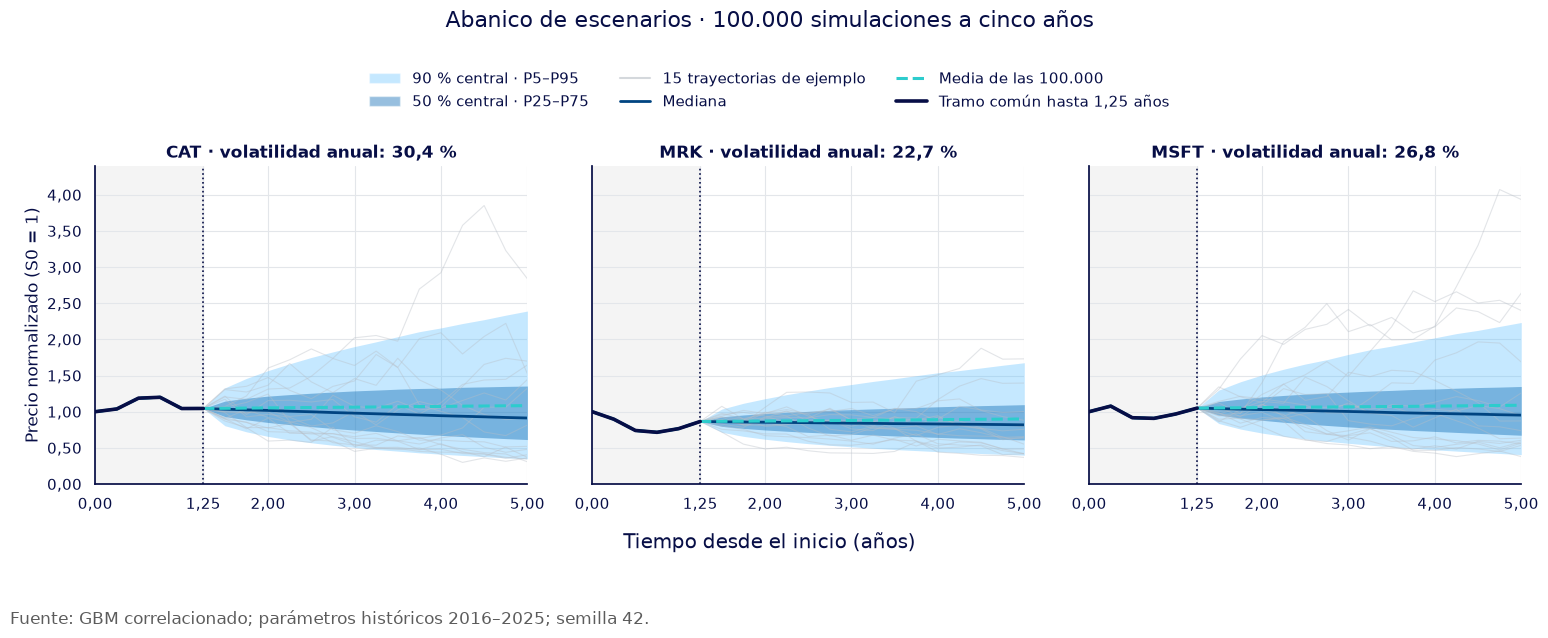

PosixPath('Graficos/redes_abanico_100000_cinco_anos.png')

In [5]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

tiempos_abanico = np.r_[0, tiempos]
X_abanico = np.concatenate((np.broadcast_to(S0, (num_sims, 1, 3)), X), axis=1)
percentiles_abanico = np.percentile(X_abanico, [5, 25, 50, 75, 95], axis=0)
media_abanico = X_abanico.mean(axis=0)
indices_ejemplo = np.linspace(0, num_sims - 1, 15, dtype=int)
limite_y = max(percentiles_abanico[-1].max(), X_abanico[indices_ejemplo].max()) * 1.08
formato_abanico = plt.FuncFormatter(lambda valor, _: fmt_es(valor, 2))

fig_abanico, axes_abanico = plt.subplots(
    1, 3, figsize=(15.5, 6), sharey=True, facecolor=BBVA["blanco"]
)

def dibujar_abanico(ax, k):
    ax.axvspan(0, t_bifurcacion, color=BBVA["gris"], zorder=0)
    ax.fill_between(tiempos_abanico, percentiles_abanico[0, :, k],
                    percentiles_abanico[4, :, k], color=BBVA["cielo"], alpha=0.35, linewidth=0)
    ax.fill_between(tiempos_abanico, percentiles_abanico[1, :, k],
                    percentiles_abanico[3, :, k], color=BBVA["medio"], alpha=0.45, linewidth=0)
    ax.plot(tiempos_abanico, X_abanico[indices_ejemplo, :, k].T,
            color=BBVA["gris_dato"], alpha=0.4, linewidth=0.8)
    ax.plot(tiempos_abanico, percentiles_abanico[2, :, k], color=BBVA["principal"], linewidth=2)
    ax.plot(tiempos_abanico, media_abanico[:, k], "--", color=BBVA["agua"], linewidth=2.2)
    ax.plot(tiempos_abanico[:n_pasos_comunes + 1],
            X_abanico[0, :n_pasos_comunes + 1, k], color=BBVA["marino"], linewidth=2.6)
    ax.axvline(t_bifurcacion, color=BBVA["marino"], linestyle=":", linewidth=1.2)
    ax.set_title(f"{activos[k]} · volatilidad anual: {fmt_es(100 * sigma[k], 1)} %",
                 fontsize=12, loc="center")
    ax.set(xlim=(0, TTM), ylim=(0, limite_y), xticks=[0, t_bifurcacion, 2, 3, 4, 5])
    ax.xaxis.set_major_formatter(formato_abanico)
    ax.yaxis.set_major_formatter(formato_abanico)

dibujar_abanico(axes_abanico[0], 0)
dibujar_abanico(axes_abanico[1], 1)
dibujar_abanico(axes_abanico[2], 2)
axes_abanico[0].set_ylabel("Precio normalizado (S0 = 1)")
fig_abanico.legend(handles=[
    Patch(facecolor=BBVA["cielo"], alpha=0.35, label="90 % central · P5–P95"),
    Patch(facecolor=BBVA["medio"], alpha=0.45, label="50 % central · P25–P75"),
    Line2D([], [], color=BBVA["gris_dato"], alpha=0.6, label="15 trayectorias de ejemplo"),
    Line2D([], [], color=BBVA["principal"], linewidth=2, label="Mediana"),
    Line2D([], [], color=BBVA["agua"], linestyle="--", linewidth=2.2, label="Media de las 100.000"),
    Line2D([], [], color=BBVA["marino"], linewidth=2.6, label="Tramo común hasta 1,25 años"),
], loc="upper center", bbox_to_anchor=(0.5, 0.91), ncol=3, frameon=False, labelcolor=BBVA["marino"], fontsize=11)
fig_abanico.suptitle("Abanico de escenarios · 100.000 simulaciones a cinco años", fontsize=16, y=0.99, color=BBVA["marino"])
fig_abanico.supxlabel("Tiempo desde el inicio (años)", y=0.085, color=BBVA["marino"])
fig_abanico.subplots_adjust(left=0.065, right=0.985, bottom=0.2, top=0.73, wspace=0.15)
cerrar_grafico(fig_abanico, "redes_abanico_100000_cinco_anos", fuente=f"GBM correlacionado; parámetros históricos 2016–2025; semilla {semilla}.", ajustar_titulos=False)


## 4. Primeras cinco trayectorias y cierres anuales

La tabla recoge los precios normalizados de las primeras cinco simulaciones al cierre de los años **1, 2, 3, 4 y 5**. Las columnas **Simulación** y **Año** identifican cada observación. Estos años son tiempos relativos desde el inicio de la simulación, distintos de las fechas del histórico.

El gráfico representa un abanico de cinco trayectorias por activo, todas con origen en $S_0=1$ y con los mismos precios hasta el quinto paso, en $t=1,25$. Después se separan por los incrementos independientes de cada continuación. Se incluyen los 20 pasos trimestrales y el instante inicial. Por este motivo, los precios del cierre del año 1 son iguales entre simulaciones. Las primeras cinco trayectorias son ejemplos visuales; la valoración condicionada utiliza las 100.000 continuaciones.


In [6]:
df_precios_anuales = pd.DataFrame(
    X[:5, indices_anuales, :].reshape(25, 3),
    index=pd.MultiIndex.from_product(
        [simulaciones[:5], anios], names=["Simulación", "Año"]
    ),
    columns=activos,
).reset_index()
display(
    Markdown("**Primeras cinco simulaciones: precios normalizados al cierre de cada año**"),
    df_precios_anuales.round(4),
)


**Primeras cinco simulaciones: precios normalizados al cierre de cada año**

,Simulación,Año,CAT,MRK,MSFT
0,1,1,"1,043800","0,765400","0,967700"
1,1,2,"0,919200","0,992900","0,882900"
2,1,3,"1,074700","1,043600","1,120100"
3,1,4,"1,050600","1,150300","1,132200"
4,1,5,"1,445400","0,880600","1,259000"
5,2,1,"1,043800","0,765400","0,967700"
6,2,2,"0,815900","0,812400","1,184000"
7,2,3,"0,811700","0,681200","1,074100"
8,2,4,"0,654100","0,685600","0,901300"
9,2,5,"0,420500","0,485000","0,663900"


Guardado: Graficos/redes_primeras_cinco_trayectorias.png


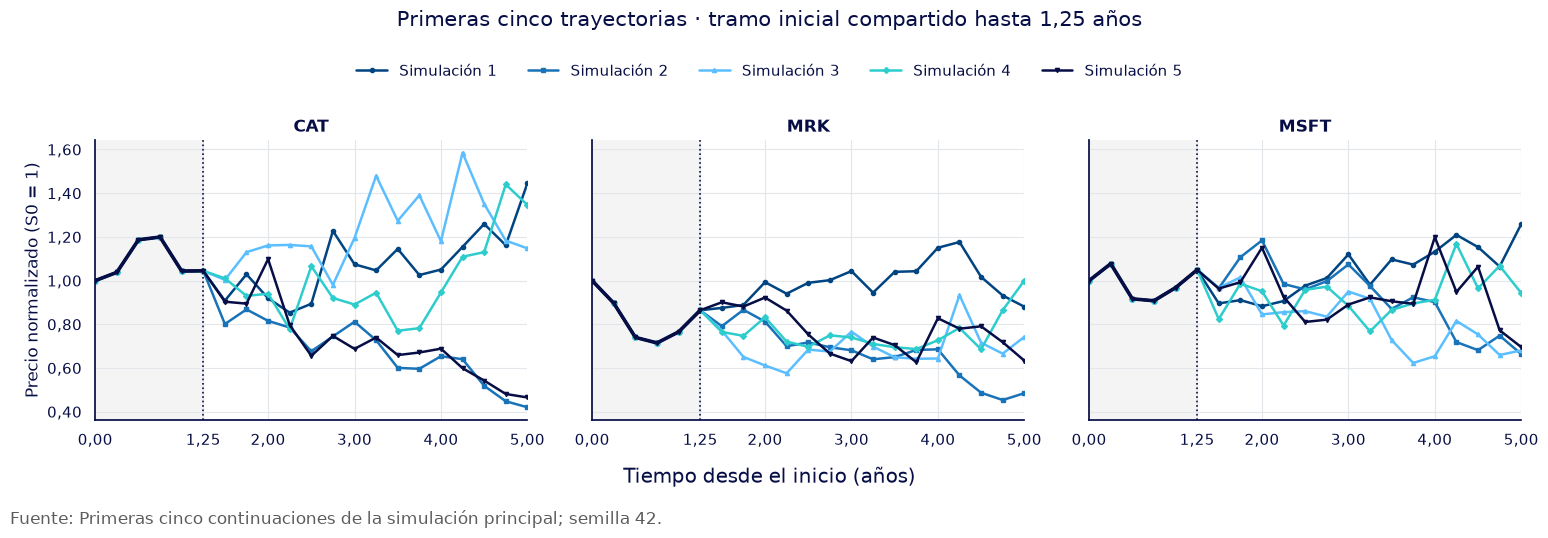

PosixPath('Graficos/redes_primeras_cinco_trayectorias.png')

In [7]:
tiempos_con_t0 = np.r_[0, tiempos]
X_ejemplos = np.concatenate((np.broadcast_to(S0, (5, 1, 3)), X[:5]), axis=1)

fig_ejemplos, axes_ejemplos = plt.subplots(1, 3, figsize=(15.5, 5), sharey=True)

def dibujar_ejemplos(ax, k):
    ax.set_prop_cycle(color=PALETA, marker=["o", "s", "^", "D", "v"])
    ax.plot(tiempos_con_t0, X_ejemplos[:, :, k].T, linewidth=1.8, markersize=3)
    ax.axvspan(0, t_bifurcacion, color=BBVA["gris"], zorder=0)
    ax.plot(tiempos_con_t0[:n_pasos_comunes + 1],
            X_ejemplos[0, :n_pasos_comunes + 1, k], color=BBVA["marino"], linewidth=2.6, marker="")
    ax.axvline(t_bifurcacion, color=BBVA["marino"], linestyle=":", linewidth=1.2)
    ax.set_title(activos[k], fontsize=12, loc="center")
    ax.set(xlim=(0, TTM), xticks=[0, t_bifurcacion, 2, 3, 4, 5])
    ax.xaxis.set_major_formatter(formato_abanico)
    ax.yaxis.set_major_formatter(formato_abanico)

dibujar_ejemplos(axes_ejemplos[0], 0)
dibujar_ejemplos(axes_ejemplos[1], 1)
dibujar_ejemplos(axes_ejemplos[2], 2)
axes_ejemplos[0].set_ylabel("Precio normalizado (S0 = 1)")
fig_ejemplos.legend(axes_ejemplos[0].lines[:5],
    np.char.add("Simulación ", np.arange(1, 6).astype(str)),
    loc="upper center", bbox_to_anchor=(0.5, 0.91), ncol=5, frameon=False, labelcolor=BBVA["marino"])
fig_ejemplos.suptitle("Primeras cinco trayectorias · tramo inicial compartido hasta 1,25 años", fontsize=15, y=0.99, color=BBVA["marino"])
fig_ejemplos.supxlabel("Tiempo desde el inicio (años)", y=0.035, color=BBVA["marino"])
fig_ejemplos.subplots_adjust(left=0.065, right=0.985, bottom=0.17, top=0.73, wspace=0.15)
cerrar_grafico(fig_ejemplos, "redes_primeras_cinco_trayectorias", fuente=f"Primeras cinco continuaciones de la simulación principal; semilla {semilla}.", ajustar_titulos=False)


## 5. Cálculo del payoff y valoración condicionada

La opción es asiática porque su pago depende de los precios observados durante la trayectoria. Para cada simulación se calcula la media geométrica de los **20 precios normalizados** de cada activo, incluidos los cinco pasos comunes, y después se suman las tres medias:

$$
G_k=\exp\left(\frac{1}{20}\sum_{j=1}^{20}
\ln\frac{S_j^k}{S_0^k}\right),
\qquad
V_T=\max(G_1+G_2+G_3-3,0).
$$

La media se toma **a lo largo del tiempo para cada activo**, no entre los tres activos en un mismo instante. La parte positiva del resultado aplica el strike 3 y garantiza un payoff no negativo. Los payoffs de cero también se incluyen en la valoración.

Al fijar la historia común $H$ hasta $t_c=1,25$, las 100.000 continuaciones estiman el pago esperado **condicionado a esa historia**. La prima en el final del tramo común se obtiene mediante:

$$
\widehat V_{t_c\mid H}=e^{-r(T-t_c)}
\frac{1}{N}\sum_{h=1}^{N}V_T^{(h)}.
$$

También se muestra la media descontada a $t=0$, $e^{-rT}\overline V_T$. Es un resultado condicionado al tramo elegido, **no una prima inicial incondicional**, porque no se promedian posibles historias distintas de los cinco primeros pasos.

El resumen incluye ambos valores, el payoff medio, los porcentajes de pagos positivos y nulos y el error estándar de la media descontada a $t=0$. Ese error cuantifica el muestreo de las continuaciones, manteniendo fijo el tramo común.


In [8]:
medias_geometricas = mc.medias_geometricas(X)
payoff = mc.calcular_payoff(X)
primas_t0 = payoff * np.exp(-r * TTM)
prima_t0 = primas_t0.mean()
prima_bifurcacion = payoff.mean() * np.exp(-r * (TTM - t_bifurcacion))
error_estandar = primas_t0.std(ddof=1) / np.sqrt(num_sims)

df_payoffs = pd.DataFrame(
    medias_geometricas, index=simulaciones,
    columns=np.char.add("Media geométrica ", np.asarray(activos)),
)
df_payoffs["Suma de medias"] = medias_geometricas.sum(axis=1)
df_payoffs["Payoff final"] = payoff
df_payoffs["Payoff descontado a t=0"] = primas_t0
display(Markdown("**Payoffs de las primeras cinco continuaciones**"), df_payoffs.head(5).round(6))

df_resumen = pd.DataFrame({
    "Resultado": [
        "Media descontada a t=0 (tramo común fijado)",
        "Prima condicionada en t=1,25 años",
        "Payoff medio al vencimiento",
        "Payoff positivo (%)", "Payoff cero (%)",
        "Error estándar de la media descontada a t=0",
    ],
    "Valor": [
        prima_t0, prima_bifurcacion, payoff.mean(),
        100 * (payoff > 0).mean(), 100 * (payoff == 0).mean(), error_estandar,
    ],
})
display(Markdown("**Resumen de las 100.000 continuaciones con el mismo tramo inicial**"), df_resumen.round(6))


**Payoffs de las primeras cinco continuaciones**

,Media geométrica CAT,Media geométrica MRK,Media geométrica MSFT,Suma de medias,Payoff final,Payoff descontado a t=0
Simulación,,,,,,
1,"1,076804","0,937171","1,024081","3,038057","0,038057","0,036200"
2,"0,749549","0,683181","0,922822","2,355552","0,000000","0,000000"
3,"1,185601","0,714959","0,843356","2,743915","0,000000","0,000000"
4,"1,011893","0,765476","0,938971","2,716339","0,000000","0,000000"
5,"0,776183","0,765510","0,936164","2,477857","0,000000","0,000000"


**Resumen de las 100.000 continuaciones con el mismo tramo inicial**

,Resultado,Valor
0,Media descontada a t=0 (tramo común fijado),"0,154328"
1,"Prima condicionada en t=1,25 años","0,156269"
2,Payoff medio al vencimiento,"0,162241"
3,Payoff positivo (%),"38,908000"
4,Payoff cero (%),"61,092000"
5,Error estándar de la media descontada a t=0,"0,000905"


## 6. Payoffs descontados por fecha: matriz Y

El valor descontado de cada trayectoria en un instante se obtiene descontando su payoff final hasta esa fecha:

$$
t_j=j\Delta t,\qquad
Y_{h,j}=V_T^{(h)}e^{-r(20-j)\Delta t}
       =V_T^{(h)}e^{-r(T-t_j)}.
$$

El código utiliza tiempos expresados en años. Por ello, **TTM - tiempos** ya es el tiempo restante hasta el vencimiento y no se vuelve a multiplicar por $\Delta t$.

**Y** tiene forma **(100000, 20)**. La fila $h$ mantiene la correspondencia con la trayectoria $h$ de X y la columna $j$ corresponde al mismo instante trimestral. En el vencimiento, $Y_{h,20}=V_T^{(h)}$.

**df_primas** conserva las 20 fechas y todas las simulaciones. **df_primas_anuales** muestra el valor descontado en $t=0$ y los cinco cierres anuales de las primeras cinco trayectorias, junto con la media de las 100.000 simulaciones.

Cada elemento de Y es un **payoff realizado descontado**. La media en $t=0$ es el pago esperado condicionado al tramo común, descontado al origen. En $t=1,25$, la media de Y coincide con la prima condicionada al final de ese tramo. La evolución por fecha de una trayectoria refleja únicamente el descuento de su mismo payoff final: no representa una revaloración con nueva información en cada fecha.

Aunque los precios iniciales sean compartidos, los payoffs y los elementos de Y pueden ser distintos, porque dependen también de los 15 pasos posteriores.


In [9]:
Y = mc.calcular_Y(payoff)
df_primas = pd.DataFrame(
    Y, index=simulaciones, columns=pd.Index(tiempos, name="Año")
)

df_primas_anuales = pd.DataFrame(
    np.vstack((primas_t0[:5], Y[:5, indices_anuales].T)),
    index=pd.Index(np.r_[0, anios], name="Año"),
    columns=np.char.add("Simulación ", np.arange(1, 6).astype(str)),
)
df_primas_anuales["Media de 100.000"] = np.r_[
    prima_t0, Y[:, indices_anuales].mean(axis=0)
]
display(Markdown("**Payoffs descontados por fecha: inicio y cierre de cada año**"), df_primas_anuales.round(6))


**Payoffs descontados por fecha: inicio y cierre de cada año**

,Simulación 1,Simulación 2,Simulación 3,Simulación 4,Simulación 5,Media de 100.000
Año,,,,,,
0,"0,036200","0,000000","0,000000","0,000000","0,000000","0,154328"
1,"0,036564","0,000000","0,000000","0,000000","0,000000","0,155879"
2,"0,036932","0,000000","0,000000","0,000000","0,000000","0,157446"
3,"0,037303","0,000000","0,000000","0,000000","0,000000","0,159028"
4,"0,037678","0,000000","0,000000","0,000000","0,000000","0,160626"
5,"0,038057","0,000000","0,000000","0,000000","0,000000","0,162241"


## 7. Distribución de los payoffs positivos

Se representan solo los payoffs **mayores que cero**, para que la masa de ceros no oculte su distribución. El título indica el porcentaje de simulaciones con payoff cero y el resumen anterior incluye ambos porcentajes. Los ceros **sí se incluyen** al calcular la prima media.


Guardado: Graficos/redes_distribucion_payoffs_positivos.png


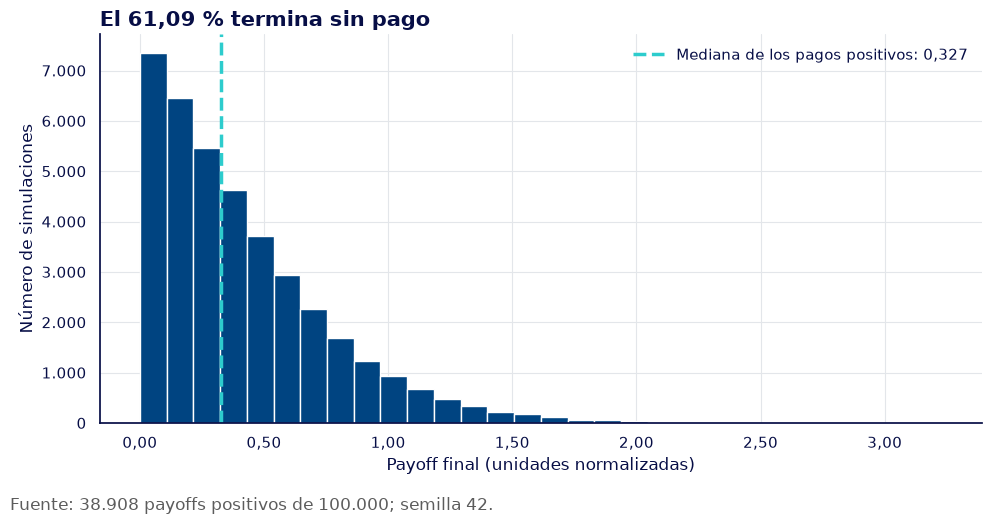

PosixPath('Graficos/redes_distribucion_payoffs_positivos.png')

In [10]:
payoffs_positivos = payoff[payoff > 0]
mediana_positivos = np.median(payoffs_positivos)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(payoffs_positivos, bins=30, color=BBVA["principal"], edgecolor=BBVA["blanco"])
ax.axvline(mediana_positivos, color=BBVA["agua"], linewidth=2.5, linestyle="--",
           label=f"Mediana de los pagos positivos: {fmt_es(mediana_positivos, 3)}")
ax.set_xlabel("Payoff final (unidades normalizadas)")
ax.set_ylabel("Número de simulaciones")
ax.set_title(
    f"El {fmt_es(100 * (payoff == 0).mean(), 2)} % termina sin pago",
    fontsize=15, loc="left",
)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: fmt_es(valor, 2)))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: fmt_es(valor)))
ax.legend(labelcolor=BBVA["marino"])
fig.tight_layout()
cerrar_grafico(fig, "redes_distribucion_payoffs_positivos", fuente=f"{fmt_es(payoffs_positivos.size)} payoffs positivos de 100.000; semilla {semilla}.", ajustar_titulos=False)


## 8. Validación de la simulación principal

Se comprueban las dimensiones y la correspondencia entre X, payoff e Y, la reproducción exacta del tramo común y la factorización de Cholesky.

La correlación se calcula sobre los **incrementos logarítmicos de los 15 pasos posteriores**, sin contar las 100.000 repeticiones del tramo común como observaciones aleatorias independientes. La tabla contrasta la matriz simulada con la matriz histórica; la tolerancia de comprobación es 0,01 en correlación absoluta.

La media terminal se compara con la esperanza neutral al riesgo **condicionada al precio del final del tramo común**:

$$
E[S_T^k\mid H]=S_{1,25}^k\,e^{r(5-1,25)}.
$$

La desviación se expresa en errores estándar de la media terminal. Una diferencia inferior a cinco errores estándar se utiliza como comprobación de compatibilidad de Monte Carlo, no como garantía del modelo.


In [11]:
comprobaciones = np.array([
    X.shape == (num_sims, num_pasos, len(activos)),
    Y.shape == (num_sims, num_pasos),
    np.all(X[:, :n_pasos_comunes, :] == X[0, :n_pasos_comunes, :]),
    np.all(np.ptp(X[:, n_pasos_comunes, :], axis=0) > 0),
    np.array_equal(Y[:, -1], payoff),
    np.allclose(rho, rho.T),
    np.allclose(L @ L.T, rho),
])
df_validacion = pd.DataFrame({
    "Comprobación": [
        "Dimensiones de X", "Dimensiones de Y", "Cinco pasos iniciales idénticos",
        "Continuaciones distintas tras el tramo común", "Y al vencimiento coincide con el payoff",
        "Matriz rho simétrica", "Cholesky: L @ L.T reproduce rho",
    ],
    "Resultado": np.where(comprobaciones, "Correcto", "No cumple"),
})
assert comprobaciones.all(), "Revisar la estructura de la simulación."

correlacion_simulada = np.corrcoef(
    mc.retornos_log(X)[:, n_pasos_comunes:, :].reshape(-1, len(activos)), rowvar=False
)
df_correlacion_simulada = pd.DataFrame({
    "Activo 1": np.repeat(activos, len(activos)),
    "Activo 2": np.tile(activos, len(activos)),
    "Correlación objetivo": rho.ravel(),
    "Correlación simulada": correlacion_simulada.ravel(),
    "Diferencia": (correlacion_simulada - rho).ravel(),
})
assert np.max(np.abs(correlacion_simulada - rho)) < 0.01, "Revisar las correlaciones."

media_terminal = X[:, -1, :].mean(axis=0)
media_terminal_teorica = X[0, n_pasos_comunes - 1, :] * np.exp(r * (TTM - t_bifurcacion))
ee_terminal = X[:, -1, :].std(axis=0, ddof=1) / np.sqrt(num_sims)
desviacion_terminal = (media_terminal - media_terminal_teorica) / ee_terminal
df_media_terminal = pd.DataFrame({
    "Activo": activos, "Media simulada": media_terminal,
    "Esperanza condicionada": media_terminal_teorica,
    "Error estándar": ee_terminal, "Desviación (errores estándar)": desviacion_terminal,
    "Compatible (< 5 EE)": np.abs(desviacion_terminal) < 5,
})
assert np.all(np.abs(desviacion_terminal) < 5), "Revisar la media terminal condicionada."

display(Markdown("**Comprobaciones estructurales**"), df_validacion)
display(Markdown("**Correlaciones de los incrementos posteriores al tramo común**"),
        df_correlacion_simulada.round(6))
display(Markdown("**Precios terminales: simulación frente a esperanza condicionada**"),
        df_media_terminal.round(6))


**Comprobaciones estructurales**

,Comprobación,Resultado
0,Dimensiones de X,Correcto
1,Dimensiones de Y,Correcto
2,Cinco pasos iniciales idénticos,Correcto
3,Continuaciones distintas tras el tramo común,Correcto
4,Y al vencimiento coincide con el payoff,Correcto
5,Matriz rho simétrica,Correcto
6,Cholesky: L @ L.T reproduce rho,Correcto


**Correlaciones de los incrementos posteriores al tramo común**

,Activo 1,Activo 2,Correlación objetivo,Correlación simulada,Diferencia
0,CAT,CAT,"1,000000","1,000000","-0,000000"
1,CAT,MRK,"0,249833","0,250329","0,000496"
2,CAT,MSFT,"0,394764","0,394277","-0,000487"
3,MRK,CAT,"0,249833","0,250329","0,000496"
4,MRK,MRK,"1,000000","1,000000","0,000000"
5,MRK,MSFT,"0,276564","0,275926","-0,000638"
6,MSFT,CAT,"0,394764","0,394277","-0,000487"
7,MSFT,MRK,"0,276564","0,275926","-0,000638"
8,MSFT,MSFT,"1,000000","1,000000","0,000000"


**Precios terminales: simulación frente a esperanza condicionada**

,Activo,Media simulada,Esperanza condicionada,Error estándar,Desviación (errores estándar),Compatible (< 5 EE)
0,CAT,"1,083704","1,084685","0,002203","-0,445276",True
1,MRK,"0,899588","0,897447","0,001308","1,636955",True
2,MSFT,"1,089124","1,089523","0,001906","-0,209284",True


## 9. Muestra independiente de referencia

Se genera otra muestra de **100.000 trayectorias con los 20 pasos independientes entre simulaciones**, manteniendo el mismo modelo, parámetros, fechas y payoff. Se exporta como `montecarlo_independiente.npz` y se conserva como referencia de valoración. El entrenamiento de `10_Mining.ipynb` utiliza la muestra con cinco pasos comunes.

La muestra estima una **prima inicial incondicional** porque promedia también las posibles historias de los primeros cinco pasos. La simulación principal estima una valoración condicionada a una historia concreta. Sus cifras corresponden a expectativas distintas.

Se reinicia un generador con semilla 42 para reproducir la prima de referencia **0,295072**. Al reutilizar la misma semilla, ambas muestras comparten la secuencia de normales: en la simulación principal se consumen primero 15 valores para el tramo común. Por tanto, **las dos muestras no son independientes entre sí**, aunque las trayectorias dentro de esta muestra sí lo sean. Cada estimación conserva su interpretación.

El error estándar de la versión condicionada mide el ruido de las continuaciones, no la variabilidad de historias iniciales alternativas. La semilla asegura reproducibilidad, no una valoración más correcta.


In [12]:
X_referencia = mc.simular_continuaciones(None, num_sims, np.random.default_rng(semilla))
G_referencia = mc.medias_geometricas(X_referencia)
payoff_referencia = mc.calcular_payoff(X_referencia)
descontados_referencia = payoff_referencia * np.exp(-r * TTM)
prima_referencia = descontados_referencia.mean()
ee_referencia = descontados_referencia.std(ddof=1) / np.sqrt(num_sims)

df_comparacion = pd.DataFrame({
    "Diseño": ["Principal: cinco pasos comunes", "Referencia: veinte pasos independientes"],
    "Valoración": ["Condicionada al tramo común", "Incondicional"],
    "Trayectorias": [num_sims, num_sims],
    "Media descontada a t=0": [prima_t0, prima_referencia],
    "Error estándar": [error_estandar, ee_referencia],
    "Payoff medio": [payoff.mean(), payoff_referencia.mean()],
    "Payoff positivo (%)": [100 * (payoff > 0).mean(), 100 * (payoff_referencia > 0).mean()],
})
display(Markdown("**Comparación: el tramo fijado cambia la valoración estimada**"), df_comparacion.round(6))


**Comparación: el tramo fijado cambia la valoración estimada**

,Diseño,Valoración,Trayectorias,Media descontada a t=0,Error estándar,Payoff medio,Payoff positivo (%)
0,Principal: cinco pasos comunes,Condicionada al tramo común,100000,"0,154328","0,000905","0,162241","38,908000"
1,Referencia: veinte pasos independientes,Incondicional,100000,"0,295072","0,001624","0,310201","44,129000"


### Prima condicionada en cada instante de una historia de referencia

Se utiliza la **primera trayectoria de la muestra independiente** como historia de referencia. Para cada $k=0,\ldots,19$, se conservan los $k$ precios trimestrales ya observados y se simulan 100.000 continuaciones independientes desde el último precio conocido:

$$
\widehat V_{t_k\mid H_k}
=e^{-r(T-t_k)}\frac{1}{N}\sum_{h=1}^{N}V_T^{(h)},
\qquad t_k=k\Delta t.
$$

Los instantes de esta tabla van de **0 a 4,75 años**. En $T=5$ ya no queda incertidumbre futura: el valor de la opción es el payoff conocido de la historia completa.

La generación de cada muestra permanece vectorizada. El recorrido de las 20 fechas organiza las valoraciones con historias de distinta longitud. Cada fecha utiliza un generador propio con semilla **1000 + k**, sin modificar la muestra independiente de semilla 42.

La prima cambia con la información observada y no solo por el descuento de un mismo pago. La banda del gráfico representa **±1,96 errores estándar**, un intervalo aproximado de confianza de Monte Carlo para cada fecha, no un abanico de precios ni una banda de confianza simultánea.

El valor de $t=0$ de esta tabla usa semilla 1000. Puede diferir por muestreo de la prima **0,295072** calculada sobre la muestra de semilla 42.


In [13]:
filas = []
for k in range(mc.NUM_PASOS):
    historia_k = X_referencia[0, :k] if k > 0 else None
    prima, ee = mc.prima_condicionada(
        historia_k, num_sims, np.random.default_rng(1000 + k)
    )
    filas.append({
        "k": k, "Tiempo (años)": k * mc.DT,
        "Prima": prima, "Error estándar": ee,
    })

df_prima_instantes = pd.DataFrame(filas)
display(Markdown("**Primas condicionadas a lo observado en la historia de referencia**"),
        df_prima_instantes.round(6))


**Primas condicionadas a lo observado en la historia de referencia**

,k,Tiempo (años),Prima,Error estándar
0,0,"0,000000","0,295560","0,001637"
1,1,"0,250000","0,276278","0,001511"
2,2,"0,500000","0,185822","0,001193"
3,3,"0,750000","0,158681","0,001052"
4,4,"1,000000","0,122216","0,000857"
5,5,"1,250000","0,157135","0,000924"
6,6,"1,500000","0,064284","0,000540"
7,7,"1,750000","0,081226","0,000580"
8,8,"2,000000","0,057091","0,000449"
9,9,"2,250000","0,031610","0,000306"


Guardado: Graficos/prima_por_instante.png


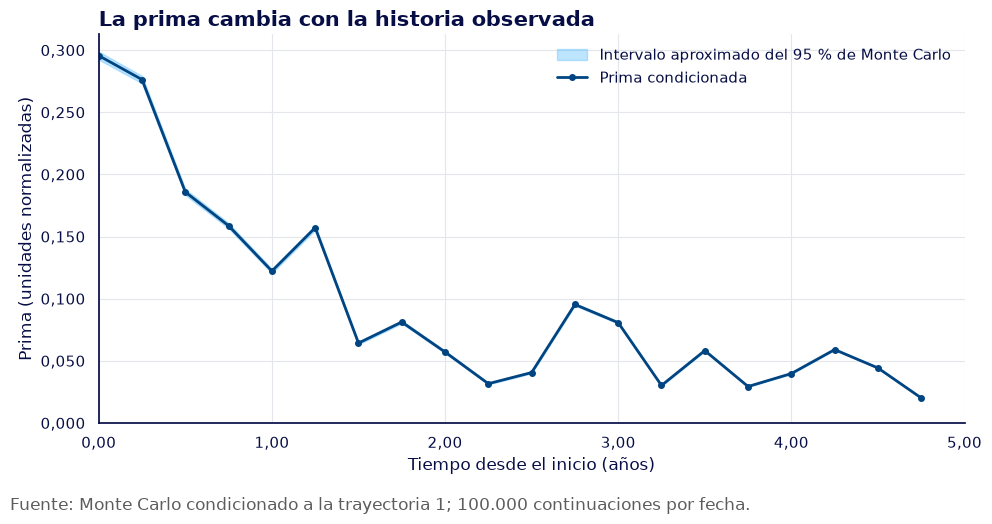

PosixPath('Graficos/prima_por_instante.png')

In [14]:
tiempos_prima = df_prima_instantes["Tiempo (años)"].to_numpy()
primas_instantes = df_prima_instantes["Prima"].to_numpy()
errores_instantes = df_prima_instantes["Error estándar"].to_numpy()

fig_primas, ax_primas = plt.subplots(figsize=(10, 5))
ax_primas.fill_between(
    tiempos_prima, primas_instantes - 1.96 * errores_instantes,
    primas_instantes + 1.96 * errores_instantes,
    color=BBVA["cielo"], alpha=0.4, label="Intervalo aproximado del 95 % de Monte Carlo",
)
ax_primas.plot(tiempos_prima, primas_instantes, "o-", color=BBVA["principal"],
               linewidth=2, markersize=4, label="Prima condicionada")
ax_primas.set_title("La prima cambia con la historia observada", fontsize=15, loc="left")
ax_primas.set_xlabel("Tiempo desde el inicio (años)")
ax_primas.set_ylabel("Prima (unidades normalizadas)")
ax_primas.set_xlim(0, TTM)
ax_primas.set_ylim(bottom=0)
ax_primas.xaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: fmt_es(valor, 2)))
ax_primas.yaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: fmt_es(valor, 3)))
ax_primas.legend(labelcolor=BBVA["marino"])
fig_primas.tight_layout()
cerrar_grafico(fig_primas, "prima_por_instante", fuente="Monte Carlo condicionado a la trayectoria 1; 100.000 continuaciones por fecha.", ajustar_titulos=False)


## 10. Contraste analítico auxiliar: asiática geométrica de CAT

Se comprueba una call geométrica sobre **CAT únicamente**, con precio inicial normalizado a 1, strike auxiliar 1 y las mismas 20 observaciones trimestrales, sin incluir $t=0$. Se utiliza la muestra independiente de la sección anterior: la fórmula incondicional no se aplica a las trayectorias con tramo fijado.

Para $n=20$, la media logarítmica tiene media $m$ y varianza $v$:

$$
m=(r-\sigma^2/2)\Delta t\frac{n+1}{2},
\qquad
v=\sigma^2\Delta t\frac{(n+1)(2n+1)}{6n}.
$$

La fórmula geométrica discreta se obtiene de esa distribución lognormal:

$$
C_0=e^{-rT}\left[e^{m+v/2}\Phi(d_1)-\Phi(d_2)\right],
\qquad
d_2=\frac{m}{\sqrt v},\quad d_1=d_2+\sqrt v.
$$

$\Phi$ es la función de distribución normal estándar. La diferencia entre Monte Carlo y la fórmula se expresa en errores estándar. El strike 1 solo pertenece a este contraste auxiliar: **la cesta principal mantiene strike 3 y no se modifica**. La fórmula de un solo activo no valora la suma de las tres medias geométricas.

Referencia matemática: [opción asiática geométrica con observación discreta](https://wanghemath.github.io/Book-MathFinance/chapters/chapter-23-exotic-options.html#discrete-geometric-asian-option-under-blackscholes).


In [15]:
from math import erf

def normal_acumulada(z):
    return 0.5 * (1 + erf(z / np.sqrt(2)))

sigma_cat = sigma[0]
m_geometrica = (r - 0.5 * sigma_cat**2) * dt * (num_pasos + 1) / 2
v_geometrica = sigma_cat**2 * dt * (num_pasos + 1) * (2 * num_pasos + 1) / (6 * num_pasos)
d2 = m_geometrica / np.sqrt(v_geometrica)
d1 = d2 + np.sqrt(v_geometrica)
prima_analitica = np.exp(-r * TTM) * (
    np.exp(m_geometrica + 0.5 * v_geometrica) * normal_acumulada(d1) - normal_acumulada(d2)
)

pagos_cat_descontados = np.maximum(G_referencia[:, 0] - 1, 0) * np.exp(-r * TTM)
prima_cat_mc = pagos_cat_descontados.mean()
ee_cat = pagos_cat_descontados.std(ddof=1) / np.sqrt(num_sims)
diferencia_cat = prima_cat_mc - prima_analitica
df_validacion_asiatica = pd.DataFrame({
    "Activo": ["CAT"], "Strike auxiliar": [1],
    "Prima Monte Carlo": [prima_cat_mc], "Prima analítica discreta": [prima_analitica],
    "Error estándar MC": [ee_cat], "Diferencia MC - analítica": [diferencia_cat],
    "Diferencia (errores estándar)": [diferencia_cat / ee_cat],
    "Compatible (< 5 EE)": [abs(diferencia_cat) < 5 * ee_cat],
})
assert abs(diferencia_cat) < 5 * ee_cat, "Revisar el contraste asiático de un solo activo."
display(Markdown("**Validación auxiliar de CAT: Monte Carlo frente a fórmula cerrada**"),
        df_validacion_asiatica.round(6))


**Validación auxiliar de CAT: Monte Carlo frente a fórmula cerrada**

,Activo,Strike auxiliar,Prima Monte Carlo,Prima analítica discreta,Error estándar MC,Diferencia MC - analítica,Diferencia (errores estándar),Compatible (< 5 EE)
0,CAT,1,"0,146487","0,146999","0,000890","-0,000512","-0,575167",True


## 11. Organización de los resultados

La muestra condicionada se conserva en **resultados_montecarlo** y es la utilizada por el entrenamiento de `10_Mining.ipynb`. La muestra independiente se conserva en **resultados_independiente** como referencia sin tramo inicial común. Ambas incluyen los parámetros utilizados y mantienen la correspondencia entre cada trayectoria y sus resultados mediante **id_simulacion**.

En `10_Mining.ipynb`, la entrada son los 20 pasos de retornos y el objetivo es un payoff final por trayectoria. Los cinco pasos comunes fijan la historia inicial sobre la que se aprende y se evalúa. Utilizar trayectorias independientes desde el origen permite estudiar otras historias iniciales, pero no es un requisito general para entrenar una red.

Los retornos de cada paso se obtienen a partir de los precios simulados:

$$
R^{\log}_{h,j,k}=\ln\frac{S^k_{h,j}}{S^k_{h,j-1}},
\qquad
R^{\mathrm{simple}}_{h,j,k}=e^{R^{\log}_{h,j,k}}-1.
$$

En el primer paso se utiliza $S_0$ como precio anterior. Los retornos son **trimestrales**, sin anualizar, y conservan la forma **(100000, 20, 3)** y el orden **CAT, MRK, MSFT**.

También se conservan **n_pasos_comunes**, **t_bifurcacion** y **trayectoria_comun** para identificar la historia compartida y distinguirla de las continuaciones.

La primera fila de cada array corresponde a la simulación 1. El primer paso representa $t=0,25$ y el último, $t=5$. Los arrays conservan los valores completos; el redondeo se aplica únicamente a las tablas mostradas.

Para estimar una prima en $t_k$, la entrada de la red solo debe contener la información observada hasta esa fecha: `X[:, :k, :]`, además del precio inicial y los parámetros conocidos. Los precios posteriores no deben entrar como predictores de esa prima.

**Y es un payoff realizado descontado, no la prima condicionada exacta de cada trayectoria.** La tabla `df_prima_instantes` proporciona referencias de valoración para una única historia observada; no contiene 100.000 primas recalculadas por fecha.

Si las primas de la trayectoria 1 se utilizan para evaluar la red, esa trayectoria debe reservarse fuera del entrenamiento y del ajuste de los escaladores. La referencia de una única historia es un control puntual, no una evaluación completa de la generalización del modelo.


In [16]:
retornos_log_simulados = mc.retornos_log(X)
retornos_simples_simulados = np.expm1(retornos_log_simulados)

resultados_montecarlo = {
    "X": X,
    "retornos_log": retornos_log_simulados,
    "retornos_simples": retornos_simples_simulados,
    "payoff": payoff,
    "Y": Y,
    "id_simulacion": simulaciones.to_numpy(),
    "tiempos": tiempos,
    "activos": np.asarray(activos),
    "S0": S0,
    "sigma": sigma,
    "rho": rho,
    "r": r,
    "TTM": TTM,
    "dt": dt,
    "strike": strike,
    "semilla": semilla,
    "num_sims": num_sims,
    "num_pasos": num_pasos,
    "n_pasos_comunes": n_pasos_comunes,
    "t_bifurcacion": t_bifurcacion,
    "trayectoria_comun": X[0, :n_pasos_comunes, :].copy(),
    "periodo_estimacion": np.array(["2016-01-05", "2025-12-31"]),
}

df_resultados = pd.DataFrame({
    "Variable": ["X", "retornos_log", "retornos_simples", "payoff", "Y", "id_simulacion", "tiempos"],
    "Forma": [
        str(X.shape), str(retornos_log_simulados.shape),
        str(retornos_simples_simulados.shape), str(payoff.shape),
        str(Y.shape), str(simulaciones.shape), str(tiempos.shape),
    ],
    "Contenido": [
        "Precios normalizados", "Retornos logarítmicos trimestrales",
        "Retornos simples trimestrales", "Payoff final por trayectoria",
        "Payoff descontado por trayectoria e instante",
        "Identificadores de las trayectorias", "Instantes en años",
    ],
})
display(Markdown("**Estructura de los resultados de Monte Carlo**"), df_resultados)

retornos_log_independientes = mc.retornos_log(X_referencia)
Y_independiente = mc.calcular_Y(payoff_referencia)

resultados_independiente = {
    "X": X_referencia,
    "retornos_log": retornos_log_independientes,
    "medias_geometricas": G_referencia,
    "payoff": payoff_referencia,
    "Y": Y_independiente,
    "id_simulacion": simulaciones.to_numpy(),
    "tiempos": tiempos,
    "activos": np.asarray(activos),
    "S0": S0,
    "sigma": sigma,
    "rho": rho,
    "r": r,
    "TTM": TTM,
    "dt": dt,
    "strike": strike,
    "semilla": semilla,
    "num_sims": num_sims,
    "num_pasos": num_pasos,
    "n_pasos_comunes": 0,
    "t_bifurcacion": 0.0,
    "periodo_estimacion": np.array(["2016-01-05", "2025-12-31"]),
}
display(Markdown("**Muestra independiente para redes: primeras cinco simulaciones**"),
        pd.DataFrame({
            "Simulación": simulaciones[:5],
            "Payoff": payoff_referencia[:5],
            "Payoff descontado a t=0": descontados_referencia[:5],
        }).round(6))


**Estructura de los resultados de Monte Carlo**

,Variable,Forma,Contenido
0,X,"(100000, 20, 3)",Precios normalizados
1,retornos_log,"(100000, 20, 3)",Retornos logarítmicos trimestrales
2,retornos_simples,"(100000, 20, 3)",Retornos simples trimestrales
3,payoff,"(100000,)",Payoff final por trayectoria
4,Y,"(100000, 20)",Payoff descontado por trayectoria e instante
5,id_simulacion,"(100000,)",Identificadores de las trayectorias
6,tiempos,"(20,)",Instantes en años


**Muestra independiente para redes: primeras cinco simulaciones**

,Simulación,Payoff,Payoff descontado a t=0
0,1,"0,038057","0,036200"
1,2,"0,000000","0,000000"
2,3,"0,000000","0,000000"
3,4,"0,440466","0,418984"
4,5,"0,000000","0,000000"


### Exportación de las muestras y de las primas de referencia

La exportación está activada. Los archivos se guardan en `Datos/Transformados/`, sin redondear los arrays:

| Archivo | Contenido y uso |
|---|---|
| `montecarlo_independiente.npz` | Muestra de referencia sin tramo inicial común: X, retornos logarítmicos, medias geométricas, payoff, Y, identificadores, fechas y parámetros. Permite comparar las valoraciones condicionada e incondicional. |
| `montecarlo_condicionado.npz` | Entrada del entrenamiento actual de `10_Mining.ipynb`: resultados de la simulación con cinco pasos comunes y sus parámetros. Conserva la simulación de la entrega original. |
| `prima_por_instante.npz` | k, tiempo, prima y error estándar para la primera historia independiente; incluye esa historia y las semillas por fecha. |

Los archivos se abren con `np.load(ruta, allow_pickle=False)`. Los `.npz` están excluidos de Git por la configuración del proyecto. Los gráficos se guardan separadamente en `Graficos/`.

La muestra condicionada es la entrada del entrenamiento de `10_Mining.ipynb`; la independiente se conserva como referencia de valoración. El archivo de primas permite contrastar la valoración de una historia concreta de la muestra independiente y la matriz Y conserva los payoffs descontados; no deben confundirse esos dos tipos de referencia.


In [17]:
exportar_resultados = True

if exportar_resultados:
    carpeta_datos = Path("Datos/Transformados")
    carpeta_datos.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(carpeta_datos / "montecarlo_independiente.npz", **resultados_independiente)
    np.savez_compressed(carpeta_datos / "montecarlo_condicionado.npz", **resultados_montecarlo)
    np.savez_compressed(
        carpeta_datos / "prima_por_instante.npz",
        k=df_prima_instantes["k"].to_numpy(),
        tiempo=df_prima_instantes["Tiempo (años)"].to_numpy(),
        prima=df_prima_instantes["Prima"].to_numpy(),
        error_estandar=df_prima_instantes["Error estándar"].to_numpy(),
        historia=X_referencia[0],
        semillas=1000 + df_prima_instantes["k"].to_numpy(),
    )
    display(pd.DataFrame({
        "Archivo generado": [
            str(carpeta_datos / "montecarlo_independiente.npz"),
            str(carpeta_datos / "montecarlo_condicionado.npz"),
            str(carpeta_datos / "prima_por_instante.npz"),
        ],
        "Uso": ["Muestra independiente para redes", "Muestra con tramo común", "Primas condicionadas de referencia"],
    }))


,Archivo generado,Uso
0,Datos/Transformados/montecarlo_independiente.npz,Muestra independiente para redes
1,Datos/Transformados/montecarlo_condicionado.npz,Muestra con tramo común
2,Datos/Transformados/prima_por_instante.npz,Primas condicionadas de referencia


## Resultados disponibles

- **X:** precios normalizados de las 100.000 trayectorias en los 20 instantes.
- **df_precios_anuales:** primeras cinco trayectorias en los cinco cierres anuales.
- **payoff** y **df_payoffs:** pagos finales y medias geométricas de cada simulación.
- **Y** y **df_primas:** payoffs descontados en los 20 instantes trimestrales.
- **df_primas_anuales:** ejemplos anuales y media de la muestra.
- **df_resumen:** valoración condicionada al tramo inicial y medidas de precisión de Monte Carlo.
- **df_validacion**, **df_correlacion_simulada** y **df_media_terminal:** comprobaciones de la simulación principal.
- **df_comparacion:** comparación entre valoración condicionada e incondicional.
- **df_validacion_asiatica:** contraste auxiliar de CAT con una fórmula cerrada.
- **resultados_montecarlo:** muestra condicionada con cinco pasos comunes.
- **resultados_independiente:** muestra independiente de referencia, con parámetros y orden de los activos.
- **df_prima_instantes:** primas recalculadas por fecha para la primera historia independiente.
- **Archivos NPZ:** exportación activada en `Datos/Transformados/`.

Los parámetros se estiman con el histórico 2016–2025 y las trayectorias representan un horizonte futuro de cinco años. Los precios y los pagos están normalizados. El error estándar cuantifica el ruido del estimador de Monte Carlo de las continuaciones bajo los parámetros y la historia inicial fijados.


## Conclusiones de los resultados

Con **100.000 continuaciones, 20 pasos trimestrales y semilla 42**, las trayectorias comparten los cinco primeros pasos hasta **1,25 años** y después se separan. El abanico muestra que la dispersión aumenta durante los 15 pasos restantes; las bandas resumen esa dispersión sin ocultar el tramo común.

El payoff medio al vencimiento es **0,162241** y la prima condicionada al final del tramo común es **0,156269**. La media descontada a $t=0$ es **0,154328**. Son valores en unidades normalizadas, no directamente en euros, y corresponden a la historia inicial fijada, no a una valoración inicial que promedie todas las historias posibles.

El **61,09 %** de las continuaciones termina con un payoff de cero y el **38,91 %** genera un pago positivo. Los precios compartidos al inicio no garantizan un pago común al final: las continuaciones posteriores determinan medias geométricas y payoffs distintos.

La media de los payoffs descontados pasa de **0,154328** en el origen a **0,162241** en el año 5. Esta diferencia se debe al menor tiempo de descuento del mismo pago final y no a un crecimiento garantizado del valor de la opción.

El error estándar de la media descontada a $t=0$ es **0,000905**. Mide la variabilidad de Monte Carlo de las continuaciones condicionadas al tramo común; no recoge la incertidumbre de los parámetros ni la variabilidad de historias iniciales alternativas.

La referencia con 20 pasos independientes estima una prima inicial incondicional de **0,295072**, con error estándar **0,001624** y **44,129 %** de pagos positivos. No contradice el resultado principal: promedia historias iniciales distintas, mientras que la simulación principal fija una sola. Cambiar el tramo común puede modificar considerablemente la valoración; aumentar las continuaciones solo reduce el ruido alrededor del valor condicionado a ese tramo.

Las verificaciones reproducen las correlaciones y los precios terminales esperados **condicionados** al tramo inicial. La prueba auxiliar sobre CAT obtiene **0,146487** por Monte Carlo frente a **0,146999** con la fórmula geométrica discreta, una diferencia de **0,58 errores estándar**. Esta comprobación valida el esquema de simulación y de promedio temporal para un solo activo, no proporciona una fórmula cerrada para la cesta.

El entrenamiento de `10_Mining.ipynb` utiliza la muestra condicionada, conservando los cinco primeros pasos comunes hasta 1,25 años. Las continuaciones posteriores varían entre trayectorias. La muestra independiente se conserva como referencia para estudiar distintas historias iniciales y comparar las valoraciones condicionada e incondicional. Ambas se exportan por separado, evitando mezclar sus interpretaciones.

La tabla de primas por instante corresponde a la primera historia de la muestra independiente y utiliza una nueva simulación condicionada para cada fecha, con solo la información observada hasta ese momento. Su evolución refleja tanto la historia conocida como el tiempo restante; no se obtiene descontando un único payoff final. Cada fecha utiliza su propia semilla, entre 1000 y 1019. El punto inicial de esta tabla puede diferir de 0,295072 por utilizar la semilla 1000 en lugar de 42.


## Comprobaciones finales

Se verifica la reproducción de las cifras de la entrega a seis decimales y de los precios comunes a cuatro decimales. También se comprueba la correspondencia entre X, payoff e Y, la variación desde el primer paso de la muestra independiente y las dimensiones de los arrays preparados para redes.


In [18]:
valores_obtenidos = np.array([
    prima_t0, prima_bifurcacion, payoff.mean(), 100 * (payoff > 0).mean(),
    prima_referencia, 100 * (payoff_referencia > 0).mean(),
])
valores_esperados = np.array([
    0.154328, 0.156269, 0.162241, 38.908000, 0.295072, 44.129000,
])
np.testing.assert_allclose(np.round(valores_obtenidos, 6), valores_esperados, rtol=0, atol=1e-12)
np.testing.assert_allclose(np.round(X[0, n_pasos_comunes - 1], 4),
                           [1.0448, 0.8644, 1.0494], rtol=0, atol=1e-12)
assert np.all(X[:, :n_pasos_comunes, :] == historia)
assert np.array_equal(Y[:, -1], payoff)
assert np.array_equal(Y_independiente[:, -1], payoff_referencia)
assert resultados_independiente["X"].shape == (num_sims, num_pasos, len(activos))
assert resultados_independiente["retornos_log"].shape == (num_sims, num_pasos, len(activos))
assert resultados_independiente["medias_geometricas"].shape == (num_sims, len(activos))
assert np.all(np.ptp(X_referencia[:, 0, :], axis=0) > 0)
assert df_prima_instantes.shape == (num_pasos, 4)
assert np.all(np.isfinite(df_prima_instantes[["Prima", "Error estándar"]].to_numpy()))

display(pd.DataFrame({
    "Resultado": [
        "Principal: media descontada a t=0", "Principal: prima en t=1,25",
        "Principal: payoff medio", "Principal: payoff positivo (%)",
        "Independiente: prima en t=0", "Independiente: payoff positivo (%)",
    ],
    "Obtenido": np.round(valores_obtenidos, 6),
    "Esperado": valores_esperados,
    "Estado": "Correcto",
}))


,Resultado,Obtenido,Esperado,Estado
0,Principal: media descontada a t=0,"0,154328","0,154328",Correcto
1,"Principal: prima en t=1,25","0,156269","0,156269",Correcto
2,Principal: payoff medio,"0,162241","0,162241",Correcto
3,Principal: payoff positivo (%),"38,908000","38,908000",Correcto
4,Independiente: prima en t=0,"0,295072","0,295072",Correcto
5,Independiente: payoff positivo (%),"44,129000","44,129000",Correcto
